# 02 · A local discontinuity with calendar effects and HAC inference

**Synthetic illustration — Not empirical research results**

A visible jump is not automatically a policy effect. This notebook shows what
the local regression estimates and how its uncertainty depends on correlated
hourly errors. It uses a known artificial jump and seeded disturbances, never
private coefficients or a calibrated empirical series.

**Learn to:** inspect the design, triangular weights and reference categories;
obtain HAC24/HAC168 intervals; and preserve elapsed hours when observations are missing.
All calculations call the existing package. See [identification and limitations](../docs/methodology.md).


In [1]:
import numpy as np
import pandas as pd
# Keep table outputs plain text for the public safety profile.
pd.set_option("display.notebook_repr_html", False)
import matplotlib.pyplot as plt
from IPython.display import display

LABEL = "Synthetic illustration — Not empirical research results"
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
DEMO_LABEL = "SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS"
print(DEMO_LABEL)
print(LABEL)


SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS
Synthetic illustration — Not empirical research results


## 1. Create a reproducible teaching series

The package fixture supplies a jump of 4 MW with different linear slopes on
either side. We add an invented daily cycle and seeded AR(1) noise. The 10-day
teaching bandwidth is deliberately smaller than the formal research grid.
Neither the seed nor noise scale was chosen using empirical results.


In [2]:
from scipy.signal import lfilter
from cbam_power._demo import artificial_native
from cbam_power.market import integrate_native
from cbam_power.design import calendar, local
from cbam_power.estimators import fit, hac

native_times, native_values = artificial_native()
hourly = integrate_native(native_times, native_values, 15,
                          "scheduled_export_proxy").reset_index()
rng = np.random.default_rng(73021)
disturbance = lfilter([1.], [1., -.65], rng.normal(0., 3., len(hourly)))
hourly["scheduled_export_proxy"] += (
    2 * np.sin(2 * np.pi * np.arange(len(hourly)) / 24) + disturbance)
teaching_sample = local(calendar(hourly), 10)
assert teaching_sample.timestamp_utc.is_unique
print("Artificial observations:", len(teaching_sample), "| known DGP jump: 4 MW")


Artificial observations: 480 | known DGP jump: 4 MW


## 2. Read the estimand from the design

$$Y_t=\alpha+\tau Post_t+\beta r_t+\gamma(Post_t r_t)
  +\text{hour FE}+\text{weekday FE}+\varepsilon_t.$$

Here $r_t$ is elapsed days at the delivery midpoint. Weighted least squares uses
$w_t=1-|r_t|/h$ inside the local window. The coefficient $\tau$ is the fitted
difference between the two limits at the cutoff, conditional on this design.
Calendar controls do not remove every event coinciding with that cutoff.


In [3]:
fitted = fit(teaching_sample, "scheduled_export_proxy", ["post", "r", "post_r"],
             fe=("hour", "weekday"), weight="triangular")
intervals = []
for lag in [24, 168]:
    covariance = fitted.covariance(lag)
    estimate = fitted.contrast(covariance, {"post": 1})
    intervals.append({"model_id": "DEMO_LOCAL_RDIT", "HAC_hours": lag, **estimate})
intervals = pd.DataFrame(intervals)
display(intervals[["model_id", "HAC_hours", "coefficient", "se", "ci_low", "ci_high"]])
print("Omitted calendar categories:", fitted.audit["references"])
print("Design rank / columns:", fitted.audit["rank"], "/", len(fitted.names))
assert fitted.audit["rank"] == len(fitted.names)


          model_id  HAC_hours  coefficient        se    ci_low   ci_high
0  DEMO_LOCAL_RDIT         24      3.45175  1.033249  1.426583  5.476917
1  DEMO_LOCAL_RDIT        168      3.45175  0.590363  2.294638  4.608862

Omitted calendar categories: {'hour': '0', 'weekday': '0'}
Design rank / columns: 33 / 33


### Inspect the observations that receive weight

The edge observations have small triangular weights. The table shows the
delivery-start key, midpoint running variable, treatment indicator and Rome
calendar used by the package. The design keeps one reference category per
calendar effect; a full-rank design is checked before inference.


                timestamp_utc         r  post  triangular  hour  weekday
0   2025-12-21 23:00:00+00:00 -9.979167   0.0    0.002083     0        0
1   2025-12-22 00:00:00+00:00 -9.937500   0.0    0.006250     1        0
239 2025-12-31 22:00:00+00:00 -0.020833   0.0    0.997917    23        2
240 2025-12-31 23:00:00+00:00  0.020833   1.0    0.997917     0        3
478 2026-01-10 21:00:00+00:00  9.937500   1.0    0.006250    22        5
479 2026-01-10 22:00:00+00:00  9.979167   1.0    0.002083    23        5

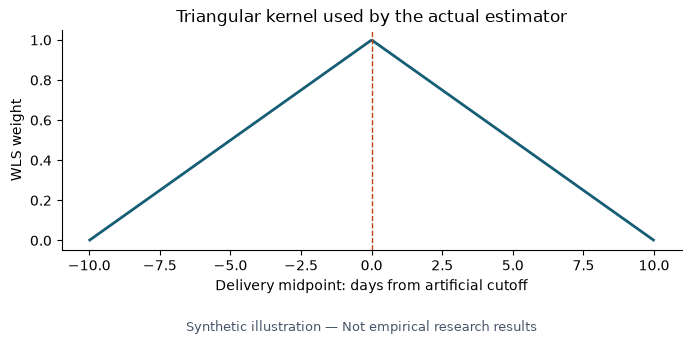

In [4]:
display(teaching_sample.iloc[[0, 1, len(teaching_sample)//2-1,
    len(teaching_sample)//2, len(teaching_sample)-2, len(teaching_sample)-1]]
    [["timestamp_utc", "r", "post", "triangular", "hour", "weekday"]])
design_figure, weight_axis = plt.subplots(figsize=(8, 3.6))
weight_axis.plot(fitted.sample.r, fitted.weights, color="#155e75", linewidth=2)
weight_axis.axvline(0, color="#c2410c", linestyle="--", linewidth=1)
weight_axis.set(xlabel="Delivery midpoint: days from artificial cutoff",
                ylabel="WLS weight", title="Triangular kernel used by the actual estimator")
design_figure.text(.5, .025, LABEL, ha="center", fontsize=9, color="#475569")
design_figure.subplots_adjust(bottom=.25, top=.86)
plt.show()


## 3. Plot saved fit components, not a second estimator

The left panel removes the fitted calendar component and shows the two local
linear pieces. The right panel uses the same coefficients with different HAC
covariance estimates. A larger lag allowance does not guarantee a wider
interval in every sample; both are properties of the residual dependence.


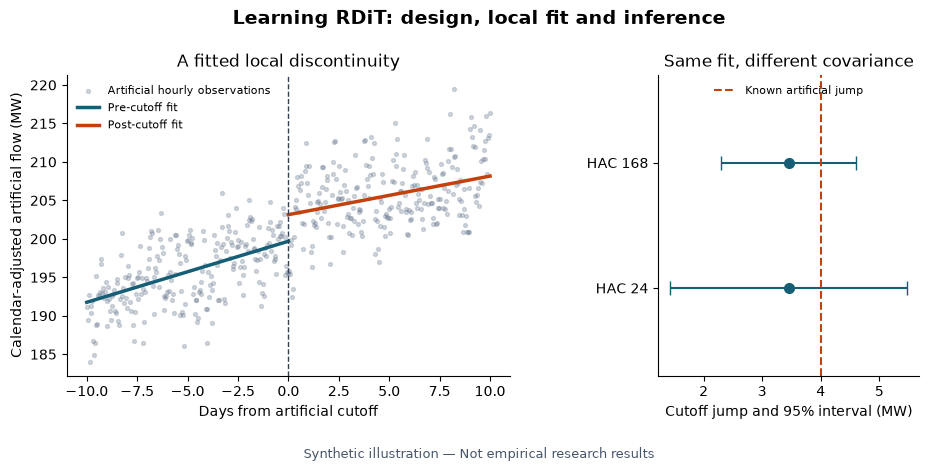

In [5]:
core_names = ["const", "post", "r", "post_r"]
core_columns = [fitted.names.index(name) for name in core_names]
calendar_part = fitted.x @ fitted.beta - fitted.x[:, core_columns] @ fitted.beta[core_columns]
adjusted = fitted.y - calendar_part
beta = dict(zip(fitted.names, fitted.beta))

figure, axes = plt.subplots(1, 2, figsize=(11, 4.7), gridspec_kw={"width_ratios": [1.7, 1]})
axes[0].scatter(fitted.sample.r, adjusted, s=8, alpha=.28, color="#64748b", label="Artificial hourly observations")
for side, bounds, color in [(0, (-10, 0), "#155e75"), (1, (0, 10), "#c2410c")]:
    grid = np.linspace(*bounds, 160)
    prediction = beta["const"] + beta["post"] * side + beta["r"] * grid + beta["post_r"] * side * grid
    axes[0].plot(grid, prediction, color=color, linewidth=2.5, label="Pre-cutoff fit" if side == 0 else "Post-cutoff fit")
axes[0].axvline(0, color="#334155", linestyle="--", linewidth=1)
axes[0].set(title="A fitted local discontinuity", xlabel="Days from artificial cutoff", ylabel="Calendar-adjusted artificial flow (MW)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
for row_number, row in intervals.iterrows():
    axes[1].errorbar(row.coefficient, row_number,
        xerr=[[row.coefficient-row.ci_low], [row.ci_high-row.coefficient]],
        fmt="o", color="#155e75", capsize=5, markersize=7)
axes[1].axvline(4, color="#c2410c", linestyle="--", label="Known artificial jump")
axes[1].set(yticks=[0, 1], yticklabels=["HAC 24", "HAC 168"],
            xlabel="Cutoff jump and 95% interval (MW)", title="Same fit, different covariance", ylim=(-.7, 1.7))
axes[1].legend(frameon=False, fontsize=8, loc="upper center")
figure.suptitle("Learning RDiT: design, local fit and inference", fontsize=14, fontweight="bold")
figure.text(.5, .025, LABEL, ha="center", fontsize=9, color="#475569")
figure.subplots_adjust(bottom=.2, top=.84, wspace=.42)
plt.show()


In [6]:
import os
from pathlib import Path

output_root = os.environ.get("CBAM_TEACHING_OUTPUT_ROOT")
if output_root:
    destination = Path(output_root).expanduser().resolve()
    # Explicit exports belong outside the source checkout. The teaching runner
    # additionally confines all writes to its private output root.
    for ancestor in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (ancestor / "pyproject.toml").is_file() and (ancestor / "src/cbam_power").is_dir():
            if destination.is_relative_to(ancestor) or ancestor.is_relative_to(destination):
                raise ValueError("TEACHING_OUTPUT_MUST_BE_OUTSIDE_CHECKOUT")
    destination.mkdir(parents=True, exist_ok=True)
    target = destination / "rdit_demo.png"
    if target.exists():
        raise FileExistsError("TEACHING_FIGURE_ALREADY_EXISTS")
    figure.savefig(target, dpi=180, facecolor="white", metadata={"Software": "Matplotlib"})
    print("Created rdit_demo.png from this artificial notebook.")


## 4. Missing hours are not adjacent observations

HAC uses a Bartlett kernel on **elapsed-hour lags**. For two one-dimensional
score contributions $[1,1]$ two hours apart, HAC lag 1 has variance sum 2:
there is no lag-1 cross product. Compressing the clock would incorrectly add 1.
This hand-check exercises the package's HAC directly; it does not reconstruct
the estimator in notebook code.


In [7]:
scores = np.ones((2, 1))
separated = pd.to_datetime(["2026-01-03T00:00Z", "2026-01-03T02:00Z"], utc=True)
compressed = pd.date_range(separated[0], periods=2, freq="h")
elapsed_variance = hac(separated, scores, 1)[0, 0]
compressed_variance = hac(compressed, scores, 1)[0, 0]
assert np.isclose(elapsed_variance, 2.)
assert np.isclose(compressed_variance, 3.)
display(pd.DataFrame({"clock": ["Real elapsed hours", "Incorrect compressed clock"],
                      "score covariance": [elapsed_variance, compressed_variance]}))


                        clock  score covariance
0          Real elapsed hours               2.0
1  Incorrect compressed clock               3.0

## Interpretation limits

HAC changes uncertainty, not identification. Time discontinuities can reflect
other concurrent shocks, market arrangements or changing support. The known
jump here is part of an artificial equation, not an estimate of CBAM's effect.
Formal V3 definitions, all model branches, samples and frozen validation remain
distinct from this one-model teaching exercise. The figure can be reproduced
by setting `CBAM_TEACHING_OUTPUT_ROOT` to a new external directory; otherwise
this notebook writes no figure file.

Continue to [fixed-weight synthetic comparisons](03_synthetic_control.ipynb)
and [robustness and validation](04_robustness_and_validation.ipynb).


## Reproducible numerical checkpoints

The following values summarize this artificial run. The teaching runner
compares them across clean-kernel executions; they are not empirical
baselines. All values come from the calculations above, with no private
inputs or fitted research values. Presentation rounding does not change
the unrounded checkpoints.


In [8]:
lag24 = intervals.set_index("HAC_hours").loc[24]
lag168 = intervals.set_index("HAC_hours").loc[168]
PUBLIC_NUMERICAL_CHECKPOINTS = {
    "example": "DEMO_RDIT_HAC", "seed": 73021,
    "sample_hours": int(len(fitted.y)), "design_rank": int(fitted.audit["rank"]),
    "design_columns": int(len(fitted.names)),
    "jump_MW": float(lag168.coefficient), "known_artificial_jump_MW": 4.,
    "HAC24_se": float(lag24.se), "HAC168_se": float(lag168.se),
    "HAC24_ci": [float(lag24.ci_low), float(lag24.ci_high)],
    "HAC168_ci": [float(lag168.ci_low), float(lag168.ci_high)],
    "kernel_weight_sum": float(fitted.weights.sum()),
    "kernel_weight_min": float(fitted.weights.min()),
    "kernel_weight_max": float(fitted.weights.max()),
    "elapsed_gap_score_covariance": float(elapsed_variance),
    "incorrect_compressed_score_covariance": float(compressed_variance)}


import json
json.dumps(PUBLIC_NUMERICAL_CHECKPOINTS, allow_nan=False, sort_keys=True)
display(pd.DataFrame({"checkpoint": list(PUBLIC_NUMERICAL_CHECKPOINTS),
                      "value": list(PUBLIC_NUMERICAL_CHECKPOINTS.values())}))


                               checkpoint  \
0                                 example   
1                                    seed   
2                            sample_hours   
3                             design_rank   
4                          design_columns   
5                                 jump_MW   
6                known_artificial_jump_MW   
7                                HAC24_se   
8                               HAC168_se   
9                                HAC24_ci   
10                              HAC168_ci   
11                      kernel_weight_sum   
12                      kernel_weight_min   
13                      kernel_weight_max   
14           elapsed_gap_score_covariance   
15  incorrect_compressed_score_covariance   

                                      value  
0                             DEMO_RDIT_HAC  
1                                     73021  
2                                       480  
3                                        33  
4   